# Workshop 2 — Results

**Team 6 — ECG anomaly detection with a 1D ResNet**

This notebook summarizes the training runs and the test-set evaluation. It only reads files produced by the scripts in `src/`:

1. `python src/train.py ...` → `runs/<run>/history.csv`, `checkpoints/model_best.pt`
2. `python src/evaluate.py` → `reports/test_*.csv` and `reports/test_*.png`

Run it from the `notebooks/` folder.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

W2 = Path.cwd().parent
RUNS, REPORTS = W2 / "runs", W2 / "reports"
sys.path.insert(0, str(W2 / "src"))
pd.set_option("display.precision", 4)

## 1. Learning curves

Run 1 (`resnet1d`): 32 base channels, lr 1e-3, weight decay 1e-4, dropout 0.3, full `pos_weight` (7.55).
Run 2 (`resnet1d_v2`, final): 16 base channels, lr 3e-4, weight decay 1e-2, dropout 0.5, `pos_weight` = sqrt(7.55) = 2.75.

The loss values of the two runs are not directly comparable because the `pos_weight` changes the scale of the loss.

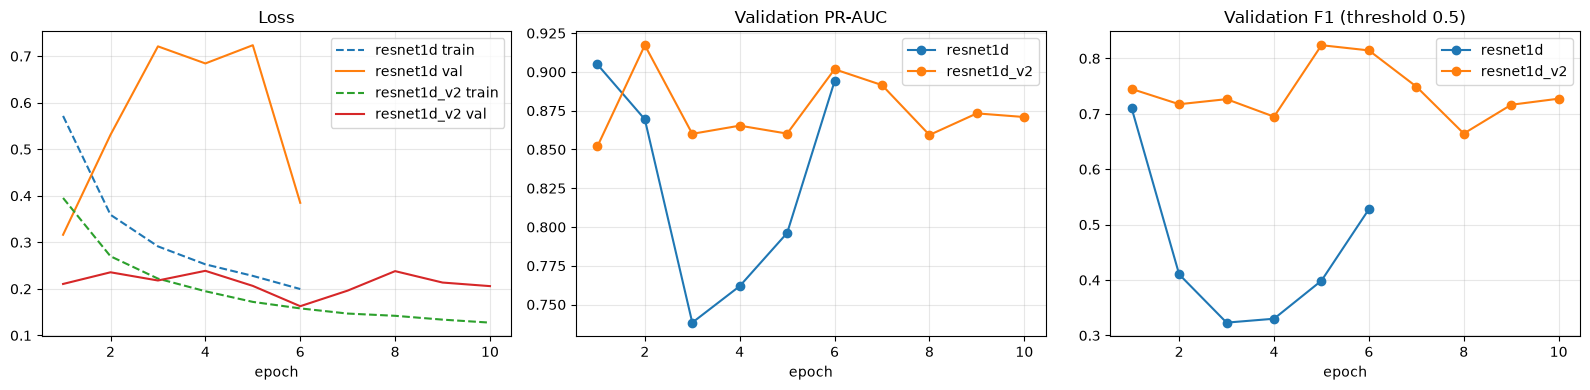

In [2]:
runs = {name: pd.read_csv(RUNS / name / "history.csv") for name in ["resnet1d", "resnet1d_v2"]}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, h in runs.items():
    axes[0].plot(h.epoch, h.train_loss, "--", label=f"{name} train")
    axes[0].plot(h.epoch, h.val_loss, label=f"{name} val")
    axes[1].plot(h.epoch, h.val_pr_auc, marker="o", label=name)
    axes[2].plot(h.epoch, h.val_f1, marker="o", label=name)
for ax, title in zip(axes, ["Loss", "Validation PR-AUC", "Validation F1 (threshold 0.5)"]):
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

,epoch,lr,train_loss,val_loss,train_precision,train_recall,train_f1,train_pr_auc,train_roc_auc,val_precision,val_recall,val_f1,val_pr_auc,val_roc_auc
0,1,0.0003,0.3953,0.2105,0.6932,0.6812,0.6871,0.7449,0.8948,0.7018,0.7936,0.7449,0.8520,0.9287
1,2,0.0003,0.2700,0.2356,0.8429,0.7774,0.8088,0.8563,0.9434,0.5941,0.9050,0.7174,0.9172,0.9695
2,3,0.0003,0.2220,0.2180,0.8489,0.8248,0.8367,0.8956,0.9627,0.6451,0.8314,0.7265,0.8601,0.9271
3,4,0.0003,0.1949,0.2388,0.8535,0.8517,0.8526,0.9147,0.9719,0.5949,0.8353,0.6949,0.8654,0.9337
4,5,0.0003,0.1720,0.2064,0.8623,0.8729,0.8676,0.9307,0.9778,0.8320,0.8159,0.8239,0.8602,0.9254
5,6,0.0003,0.1581,0.1628,0.8733,0.8869,0.8800,0.9386,0.9815,0.7811,0.8508,0.8145,0.9017,0.9622
6,7,0.0003,0.1469,0.1963,0.8759,0.8960,0.8858,0.9451,0.9839,0.6605,0.8653,0.7492,0.8915,0.9558
7,8,0.0003,0.1421,0.2381,0.8759,0.9010,0.8883,0.9486,0.9849,0.5438,0.8537,0.6644,0.8593,0.9450
8,9,0.0003,0.1339,0.2136,0.8787,0.9057,0.8920,0.9531,0.9867,0.6131,0.8614,0.7164,0.8733,0.9514
9,10,0.0002,0.1275,0.2059,0.8865,0.9076,0.8969,0.9568,0.9881,0.6325,0.8556,0.7273,0.8709,0.9503


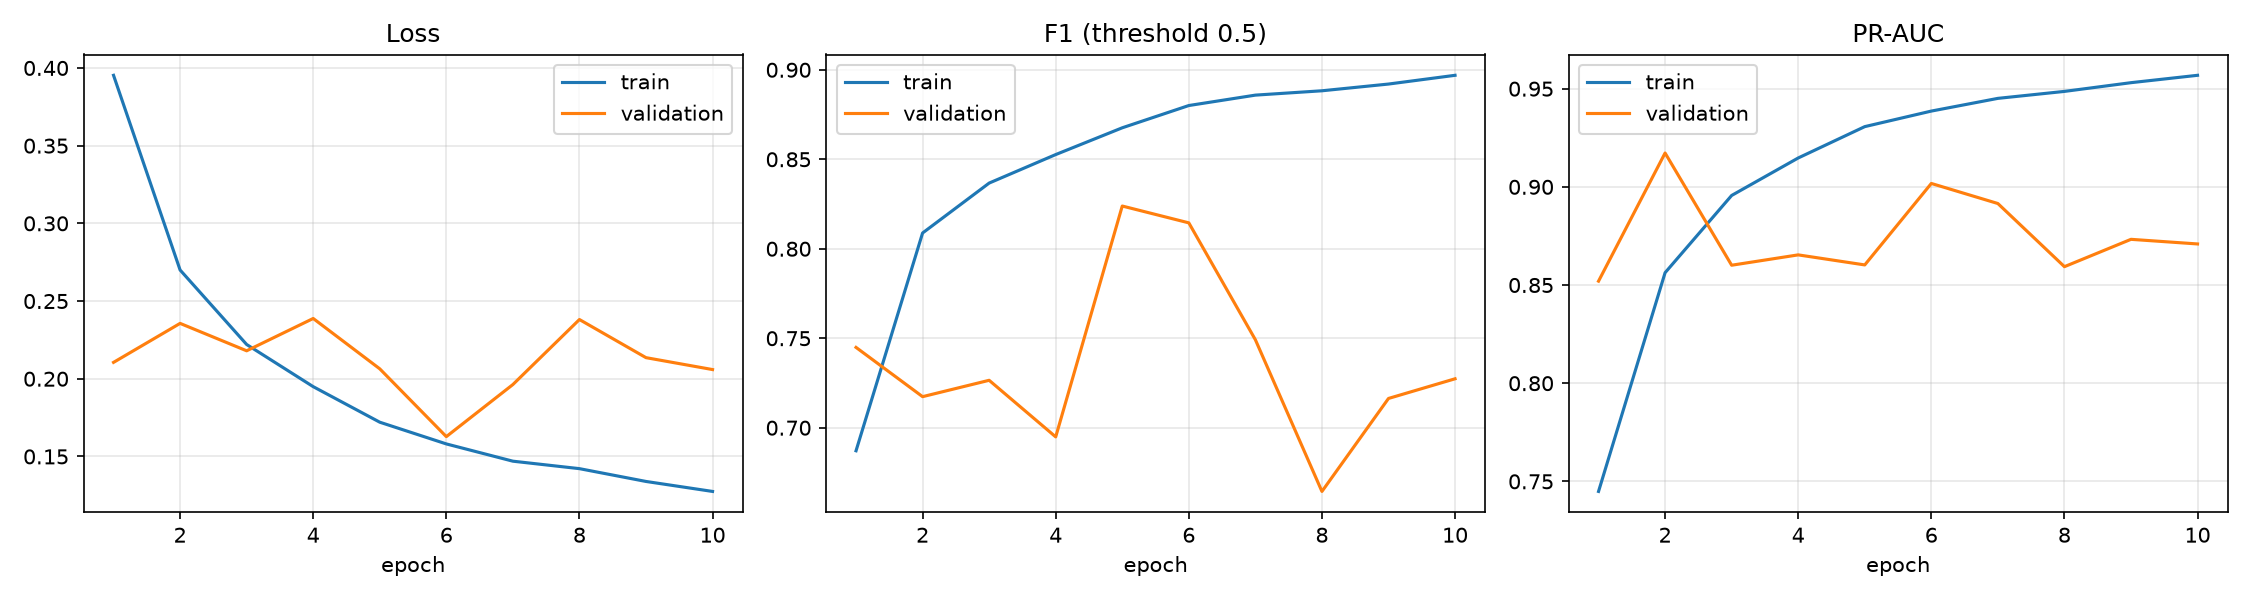

In [3]:
display(runs["resnet1d_v2"].round(4))
display(Image(str(RUNS / "resnet1d_v2" / "learning_curves.png")))

## 2. Test set: Workshop 1 baseline vs. Workshop 2

The Random Forest is reloaded from `workshop_1/models/` and evaluated on exactly the same test beats with its own threshold (0.6). The ResNet1D uses the threshold tuned on validation (0.784).

,Accuracy,Precision,Recall,F1-score,PR-AUC,ROC-AUC,Threshold
Random Forest (W1),0.9512,0.7074,0.6918,0.6995,0.7696,0.9169,0.6000
ResNet1D,0.9665,0.8140,0.7682,0.7904,0.8266,0.9078,0.7844


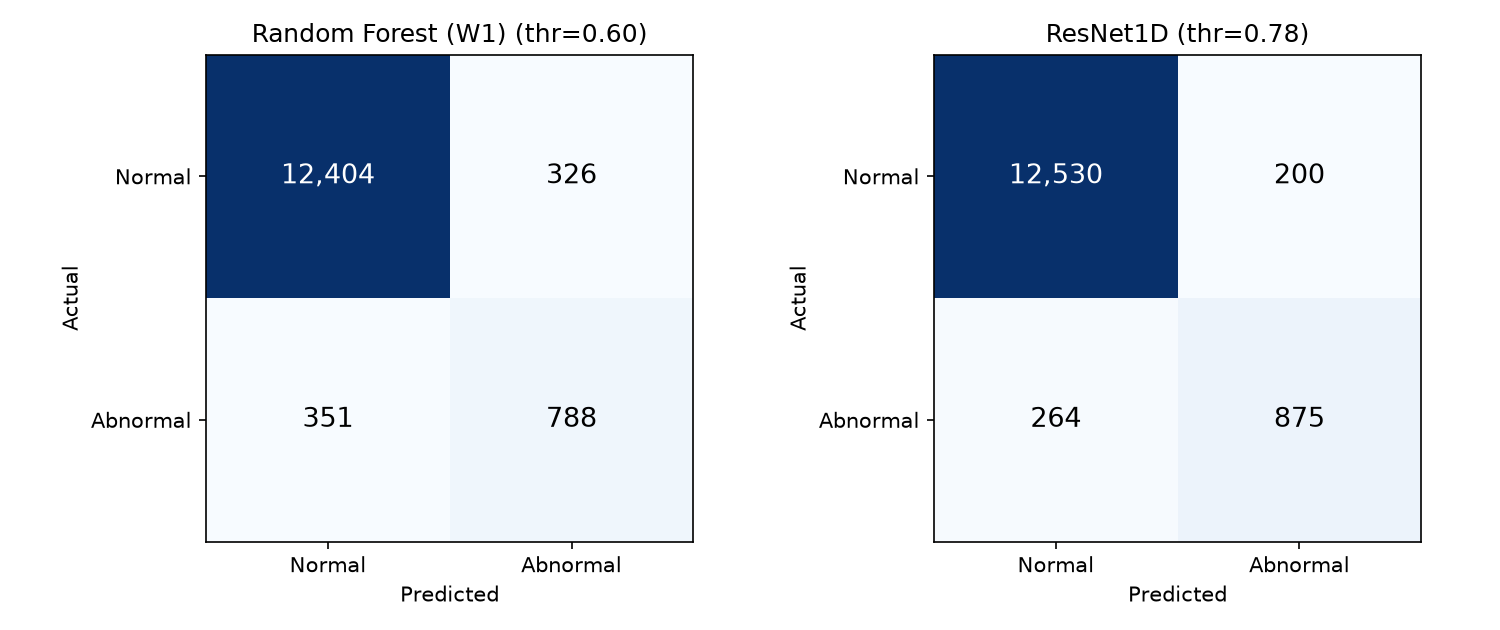

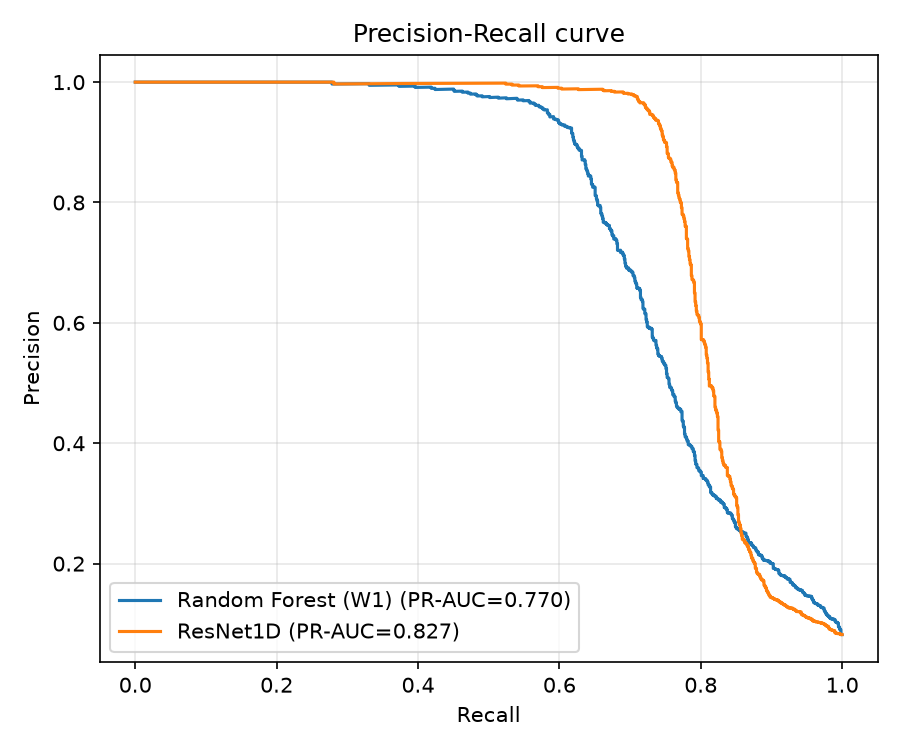

In [4]:
display(pd.read_csv(REPORTS / "test_metrics.csv", index_col=0))
display(Image(str(REPORTS / "test_confusion_matrices.png")))
display(Image(str(REPORTS / "test_pr_curves.png")))

## 3. Error analysis

**Per AAMI class.** For N the value is the false-alarm rate; for S, V and F it is the detection rate (recall).

In [5]:
display(pd.read_csv(REPORTS / "test_per_class.csv"))

,Model,AAMI class,Beats,Predicted abnormal (%),Meaning
0,Random Forest (W1),N,12730,2.56,false alarms
1,Random Forest (W1),S,219,0.00,detected (recall)
2,Random Forest (W1),V,910,86.48,detected (recall)
3,Random Forest (W1),F,10,10.00,detected (recall)
4,ResNet1D,N,12730,1.57,false alarms
5,ResNet1D,S,219,11.87,detected (recall)
6,ResNet1D,V,910,92.97,detected (recall)
7,ResNet1D,F,10,30.00,detected (recall)


**Per patient record (ResNet1D).** Record 108 is very noisy and produces most false alarms; records 201/202 (same patient) and 124 contain most of the supraventricular beats that are missed.

In [6]:
display(pd.read_csv(REPORTS / "test_per_record.csv"))

,Record,Beats,Abnormal,TP,FP,FN,Recall,Precision
0,106,2027,520,483,22,37,0.929,0.956
1,108,1763,23,2,173,21,0.087,0.011
2,115,1952,0,0,0,0,NaN,NaN
3,116,2411,110,109,5,1,0.991,0.956
4,124,1618,83,42,0,41,0.506,1.000
5,201,1963,328,219,0,109,0.668,1.000
6,202,2135,75,20,0,55,0.267,1.000


## 4. Inference with the saved checkpoint

Loads `checkpoints/model_best.pt` and classifies one full ECG record from the raw signal, using the same per-beat normalization as in training.

In [7]:
from test_model import beats_from_record, load_model, predict

model, threshold = load_model()
record = str(W2.parent / "workshop_1" / "data" / "raw" / "mitdb" / "106")
beats, peaks, true_class = beats_from_record(record)
probs, preds = predict(model, beats, threshold)

out = pd.DataFrame({"time_s": peaks / 360, "p_abnormal": probs, "pred": preds,
                    "true_aami": true_class})
print(f"{len(out)} beats, {preds.sum()} predicted abnormal, "
      f"accuracy {((out.true_aami != 'N').astype(int) == out.pred).mean():.3f}")
out.groupby("true_aami")["pred"].mean().rename("predicted abnormal (share)")

Using 2027 annotated beats from c:\Users\braya\Downloads\MachineLearning-main\MachineLearning-main\workshop_1\data\raw\mitdb\106.atr
2027 beats, 505 predicted abnormal, accuracy 0.971


true_aami
N    0.0146
V    0.9288
Name: predicted abnormal (share), dtype: float64